# Belt Road

Edit `bandage`, `preference`, `diagram_mode`, `face_colors`, and the `graph_*` options before running the cells using the **v2/.venv** kernel, with GAP on `PATH`.


In [1]:
import bce_v2 as c
from bce_v2.notebook import refresh_renderers
from IPython.display import Markdown, display

refresh_renderers()

bandage = [
    0, 0, 0,
    0, 0, 0,
    0, 0, 0,

    1, 2, 3,
    4, 0, 5,
    6, 7, 8,

    1, 2, 3,
    4, 0, 5,
    6, 7, 8,
]

preference = "memory"
diagram_mode = c.DiagramMode.OPPOSITE_CORNERS
face_colors = {
    'U': 'white', 'R': 'red', 'F': 'green',
    'D': 'yellow', 'L': 'orange', 'B': 'blue',
}

analysis = c.analyze_isotropy(bandage)
display(Markdown(
    "| Shapes | Isotropy group size | Total scrambles |\n"
    "| ---: | ---: | ---: |\n"
    f"| {analysis.loops.shape_count:,} | {analysis.group_order:,} | {analysis.colored_state_count:,} |"
))

| Shapes | Isotropy group size | Total scrambles |
| ---: | ---: | ---: |
| 84,584 | 1,492,992 | 126,283,235,328 |

Compile the staged guide. Graph rendering is a separate optional cell below.
Progress is printed while compiling. The 120-second optimization budget starts after a certified baseline is available.


# Solution from solved shape

This computational method covers all **1,492,992 reachable colored states** whose bandage shape is already the declared reference shape.

## Stages

In each stage's diagrams: face centers are colored to inform you how to orient the cube before algorithm application. Blocks already solved are dark grey. The block this stage requires you to identify is colored. Striped white color indicates a white sticker, plain white indicates unsolved sticker of any color.

| Stage | Avg moves | Worst moves |
| --- | ---: | ---: |
| Whole solution | 135.22 | 291 |
| Stage 1: Solve Pair BL-DBL | 9.50 | 19 |
| Stage 2: Solve Pair BR-DBR | 4.67 | 9 |
| Stage 3: Solve Pair FL-DFL | 8.50 | 17 |
| Stage 4: Solve Edge UB | 3.50 | 7 |
| Stage 5: Solve Edge UL | 6.17 | 12 |
| Stage 6: Solve Edge UR | 67.75 | 175 |
| Stage 7: Solve Corner UBL | 11.58 | 15 |
| Stage 8: Solve Corner UBR | 14.22 | 23 |
| Stage 9: Orient Corner UFL | 9.33 | 14 |

## Algorithms

Singmaster notation uses U/R/F/D/L/B, an apostrophe for an inverse turn, 2 for a half turn, x/y/z represent whole cube rotations 90° in the direction of an R/U/F move respectively. Structured recipes use `[A, B] = A B A⁻¹ B⁻¹`, `S^A = A⁻¹ S A`, and signed powers; a negative power executes the inverse algorithm.

| Turn sequence | Block action | Structure |
| --- | --- | --- |
| `M2: B F U2 F' B'` | `(UBR UFL)(UL UR)([BR-DBR] [FL-DFL])` | `U2^(F' B')` |
| `M3: B' F' U2 F B` | `(UBL UFR)(UL UR)([BL-DBL] [FR-DFR])` | `U2^(F B)` |
| `M4: B L U L' U' B'` | `(UBL UBR+)(UB+ UL UF+)(UFL UFR-)` | `[L, U]^B'` |
| `M5: B' R' U' R U B` | `(UBL- UBR)(UB+ UR UF+)(UFL+ UFR)` | `[R', U']^B` |
| `M6: B L F' L F L2 B'` | `(UBL UFR+)(UB UF+ UL+)(UBR+ UFL+)` | `(L L^F L2)^B'` |
| `M7: B U B' U B U2 B'` | `(UBL+ UFR)(UB UL UF)(UBR+ UFL+)` | `U^B' U U2^B'` |
| `M9: B U' F' U B' U' F` | `(UBL+ UFR UBR+ UFL+)(UB UL UF UR)` | `B U' B'^(U' F)` |
| `M10: B' R' F R' F' R2 B` | `(UBL- UFR-)(UB UF+ UR+)(UBR UFL-)` | `(R' R'^F' R2)^B` |
| `M11: B' U' B U' B' U2 B` | `(UBL- UFR-)(UB UR UF)(UBR- UFL)` | `U'^B U' U2^B` |
| `M13: B U B' L U2 L' B U' B'` | `(UBL- UFL+)(UB UR)([BL-DBL] [BR-DBR])` | `U2^(L' U'^B')` |
| `M14: B L' B' R B L B' L' R' L` | `(UBR- UFR UFL+)` | `R^(L^B') R'^L` |
| `M16: B L' B L B R B' R' L' R B R' B2 L B'` | `(UBL+ UFL+ UBR+)` | `(B L B L'^(B^R') B2)^(L B')` |

### Shared piece recipes

| Piece | Turn sequence |
| --- | --- |
| `C1` | `B L' B'` |
| `C2` | `L F' L F L2` |
| `C3` | `L B R B' R' L' R` |

| Algorithm | Recipe |
| --- | --- |
| `M2` | `(B F) (U2) (B F)^-1` |
| `M3` | `(B' F') (U2) (B' F')^-1` |
| `M4` | `(B) (L x (C1) x') (B)^-1` |
| `M5` | `(B') (R' U' R U) (B')^-1` |
| `M6` | `(B) (C2) (B)^-1` |
| `M7` | `(B) (x2 z (C2) z' x2) (B)^-1` |
| `M9` | `B U' F' x z (C1) z' x' F` |
| `M10` | `(B') (R' y2 (C1) y2 R2) (B')^-1` |
| `M11` | `(B') (U' z' (C1) z U2) (B')^-1` |
| `M13` | `(z' (C1^-1) z L) (U2) (z' (C1^-1) z L)^-1` |
| `M14` | `C1 z2 (C3) z2` |
| `M16` | `(B L') (B C3 z2 (C1) z2 B') (B L')^-1` |

## Stage 1: Solve Pair BL-DBL

This stage has 4 exact cases and 3 instruction families. It reduces the remaining possibilities from 1,492,992 to 373,248.

### Case 1

Skip — already correct

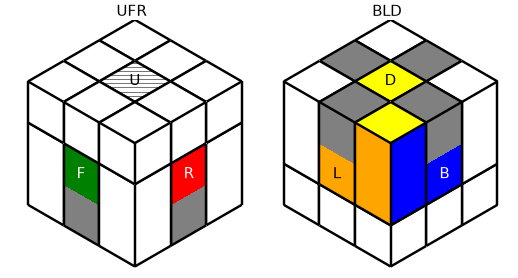

### Case 2

Execute `(y2 (M3) y2 y' (M13) y)^-1: R U R' B U2 B' R U' R' F' B' U2 B F`.

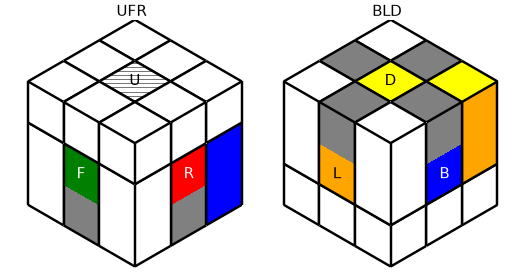

### Case 3

Execute `(y2 (M3) y2 y' (M13) y y2 (M2) y2)^-1: F B U2 B' F' R U R' B U2 B' R U' R' F' B' U2 B F`.

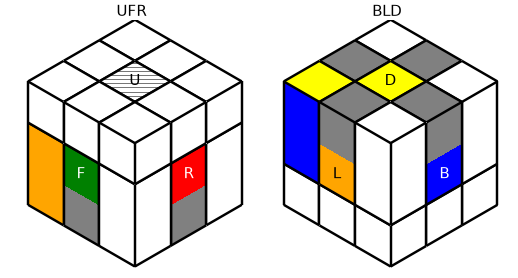

### Case 4

Execute `M3: B' F' U2 F B`.

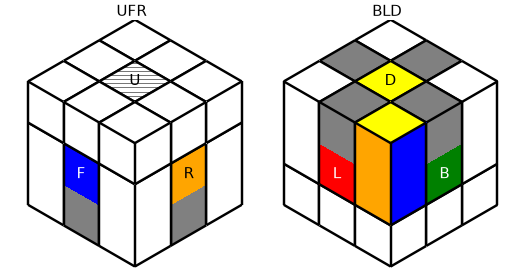

Also correct automatically after this stage: place Pair BL-DBL.

## Stage 2: Solve Pair BR-DBR

This stage has 3 exact cases and 2 instruction families. It reduces the remaining possibilities from 373,248 to 124,416.

### Case 1

Skip — already correct

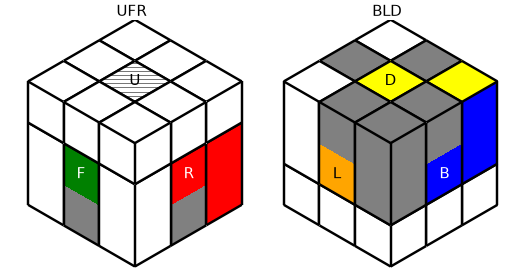

### Case 2

Execute `M2: B F U2 F' B'`.

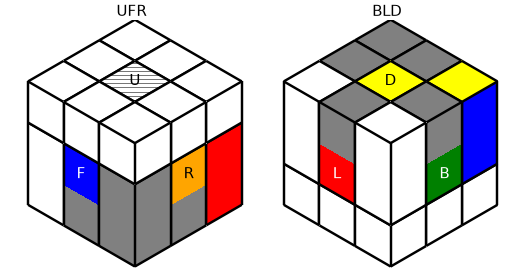

### Case 3

Execute `M13: B U B' L U2 L' B U' B'`.

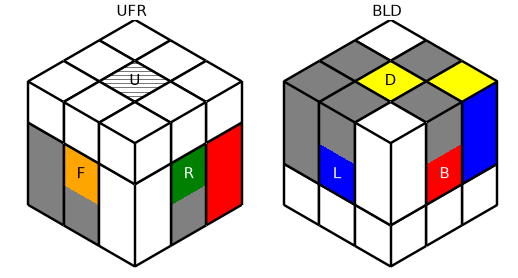

Also correct automatically after this stage: place Pair BR-DBR.

## Stage 3: Solve Pair FL-DFL

This stage has 2 exact cases and 1 instruction family. It reduces the remaining possibilities from 124,416 to 62,208.

### Case 1

Skip — already correct

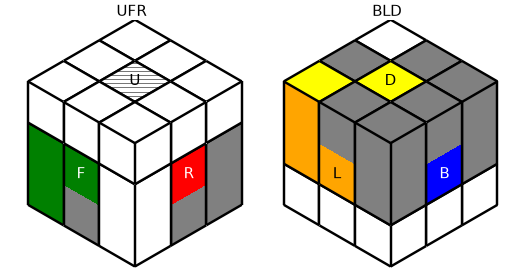

### Case 2

Execute `(M13^(M3^-1))^-1: B' F' U2 F B2 U B' L U2 L' B U' B2 F' U2 F B`.

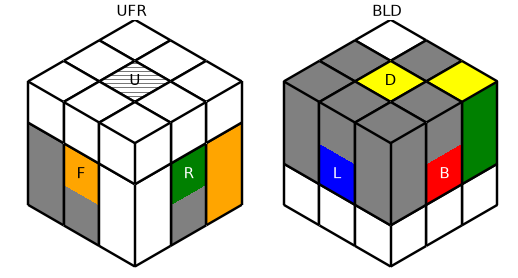

Also correct automatically after this stage: place Pair FL-DFL; place Pair FR-DFR; fully solve Pair FR-DFR.

## Stage 4: Solve Edge UB

This stage has 8 exact cases and 4 instruction families. It reduces the remaining possibilities from 62,208 to 7,776.

### Case 1

Skip — already correct

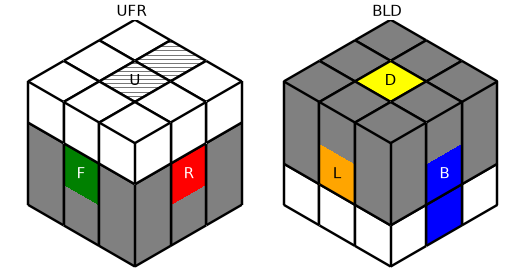

### Case 2

Execute `(U' y (M5) y')^-1: L' U' B' U B L U`.

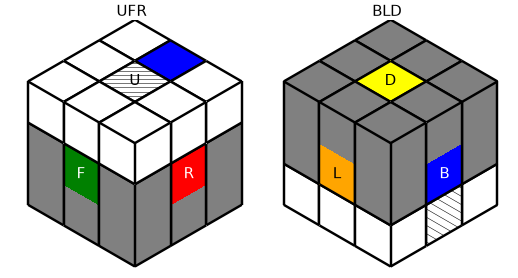

### Case 3

Execute `U: U`.

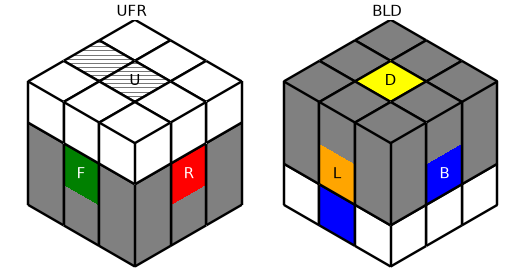

### Case 4

Execute `M5: B' R' U' R U B`.

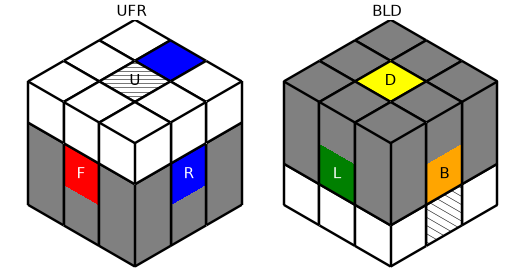

### Case 5

Execute `U': U'`.

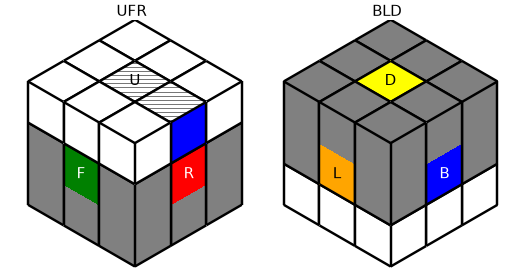

### Case 6

Execute `M5^-1: B' U' R' U R B`.

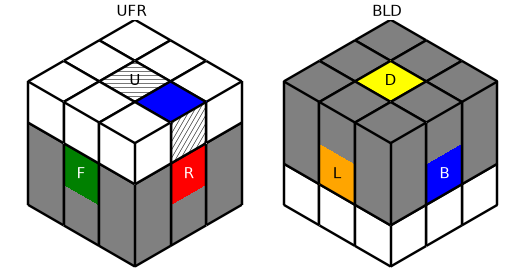

### Case 7

Execute `U2: U2`.

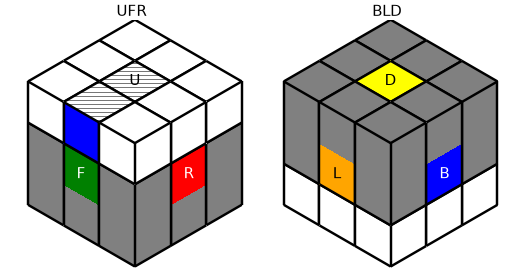

### Case 8

Execute `M5: B' R' U' R U B`.

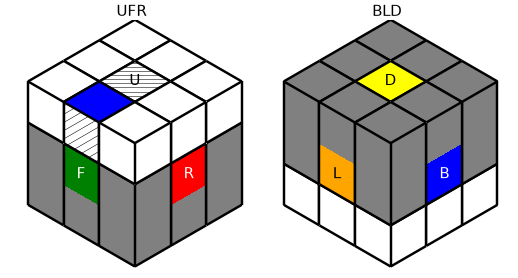

Also correct automatically after this stage: place Edge UB.

## Stage 5: Solve Edge UL

This stage has 6 exact cases and 5 instruction families. It reduces the remaining possibilities from 7,776 to 1,296.

### Case 1

Skip — already correct

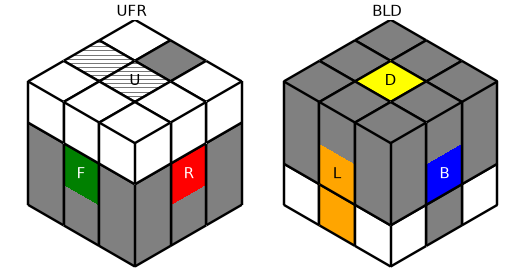

### Case 2

Execute `(y (M4) y' y' (M5) y)^-1: R' U' F' U F R L U F U' F' L'`.

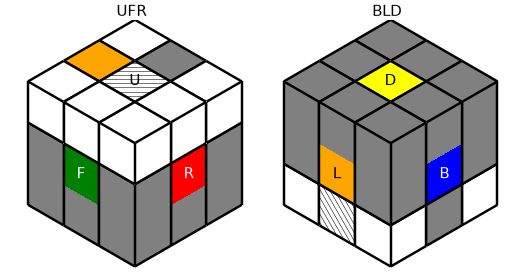

### Case 3

Execute `M6^-1: B L2 F' L' F L' B'`.

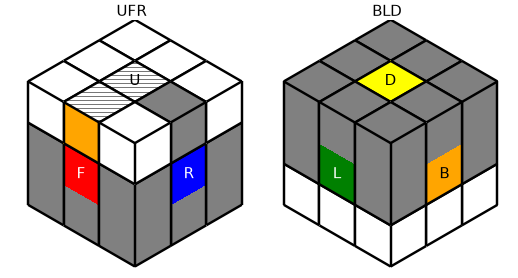

### Case 4

Execute `M4: B L U L' U' B'`.

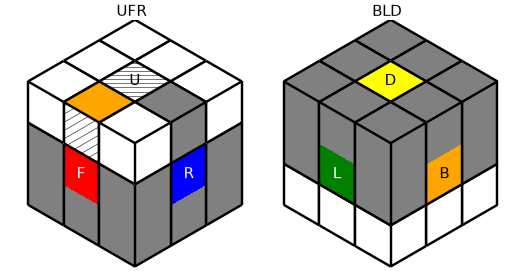

### Case 5

Execute `M5: B' R' U' R U B`.

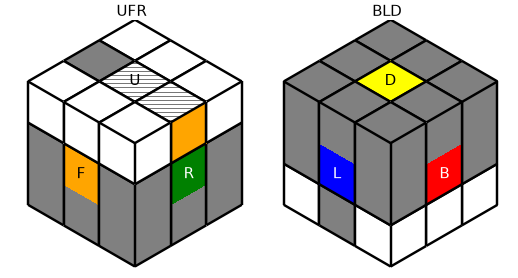

### Case 6

Execute `M4^-1: B U L U' L' B'`.

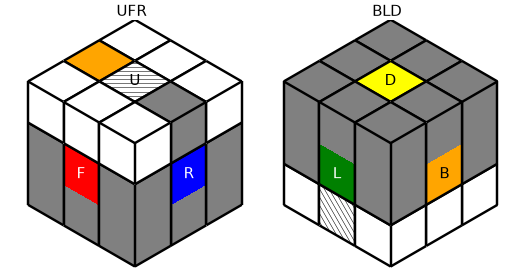

Also correct automatically after this stage: place Edge UL.

## Stage 6: Solve Edge UR

This stage has 4 exact cases and 3 instruction families. It reduces the remaining possibilities from 1,296 to 324.

### Case 1

Skip — already correct

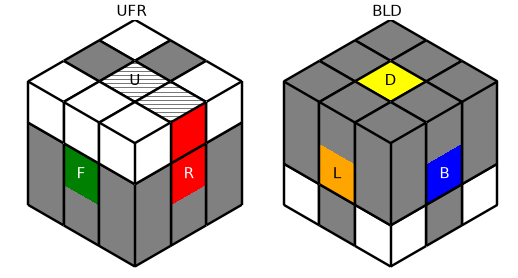

### Case 2

Execute `(M5^-1 (y2 (M4) y2)^-1)^-1: F R U R' U' F' B' R' U' R U B`.

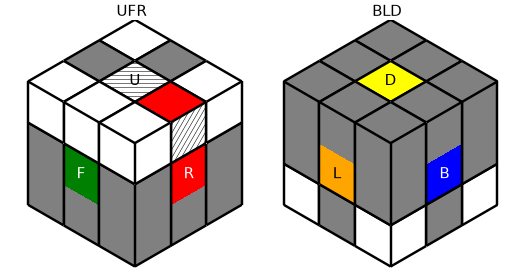

### Case 3

Execute `(y' (M2) y (y' (M9) y)^-1 y' (M4) y (y' (M9) y)^-1 (y' (M4) y)^-2 y' (M2) y (y' (M9) y)^-1 (y' (M4) y)^-1 y' (M2) y (y' (M9) y)^-1 (y' (M4) y)^-1 y' (M2) y (y' (M9) y)^-1 (y' (M4) y)^-1 y' (M2) y y' (M4) y y2 (M2) y2 (y' (M4) y)^-2 y2 (M2) y2 (y' (M4) y)^-4 y2 (M2) y2 (y' (M4) y)^-2 y2 (M2) y2 (y' (M4) y)^-1 y' (M2) y (y' (M4) y)^-2 y' (M9) y (y' (M4) y)^-3 y' (M9) y)^-1: L' U R U' L U B U B' U' B U B' U' B U B' U' R' L' U R U' L U B U B' U' B U B' U' L U2 L' B U B' U' R' F B U2 B' F' R B U B' U' B U B' U' R' F B U2 B' F' R B U B' U' B U B' U' B U B' U' B U B' U' R' F B U2 B' F' R B U B' U' B U B' U' R' F B U2 B' F' R U B U' B' L U2 L' B U B' U2 L' U R' U' L R L U2 L' B U B' U2 L' U R' U' L R L U2 L' B U B' U2 L' U R' U' L R L U2 L' B U B' U' B U B' U2 L' U R' U' L R U B U' B' U' L' U R' U' L R L U2 L' R'`.

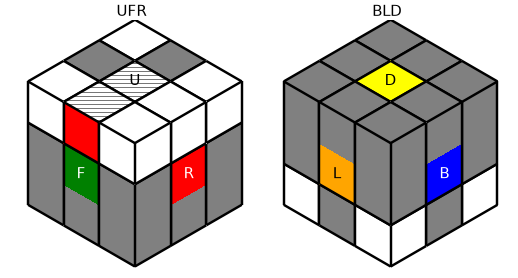

### Case 4

Execute `(y' (M4) y y' (M2) y y2 (M2) y2 (y' (M4) y)^-1 y2 (M2) y2 y' (M2) y y' (M13) y (y' (M9) y)^-1 y' (M13) y (y' (M4) y)^2 y2 (M2) y2 (y' (M4) y)^2 y2 (M2) y2 (y' (M4) y)^-1)^-1: R B U B' U' R' F B U2 B' F' R U B U' B' U B U' B' R' F B U2 B' F' R U B U' B' U B U' B' U R' B U2 B' R U2 L' U R' U' L R U R' B U2 B' R U' L U2 L' R' F B U2 B' F' R B U B' U' R' F B U2 B' F' R L U2 L' U B U' B' R'`.

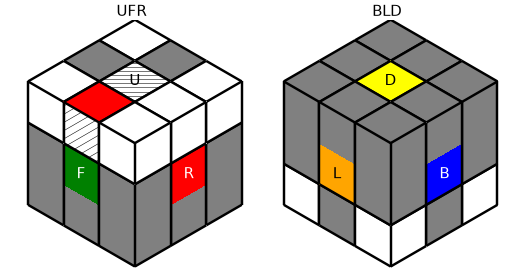

Also correct automatically after this stage: place Edge UR; place Edge UF; fully solve Edge UF.

## Stage 7: Solve Corner UBL

This stage has 12 exact cases and 11 instruction families. It reduces the remaining possibilities from 324 to 27.

### Case 1

Skip — already correct

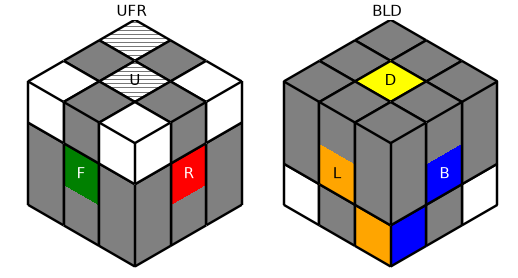

### Case 2

Execute `(y (M6) y' y' (M10) y)^-1: R' F2 L F L' F R L F2 R' F' R F' L'`.

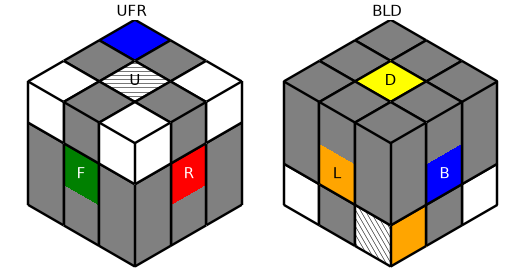

### Case 3

Execute `M7^-1 (y2 (M11) y2)^-1: B U2 B' U' B U' B' F' U2 F U F' U F`.

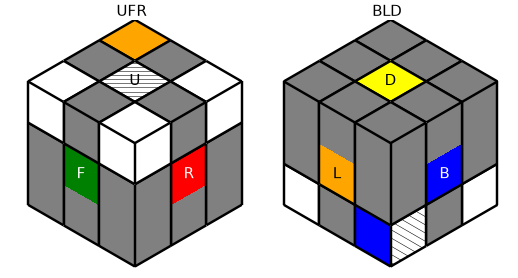

### Case 4

Execute `((y' (M14) y)^U)^-1: U' B' F B R B' R' F' R B R' U`.

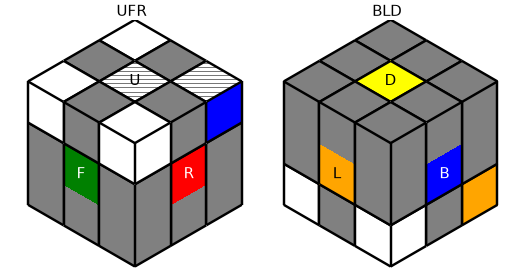

### Case 5

Execute `M5^3: B' R' U' R U R' U' R U R' U' R U B`.

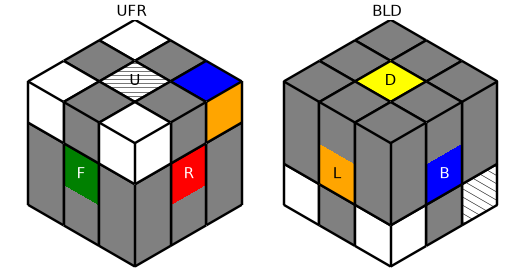

### Case 6

Execute `((y' (M14) y)^(U2))^-1: U2 B' F B R B' R' F' R B R' U2`.

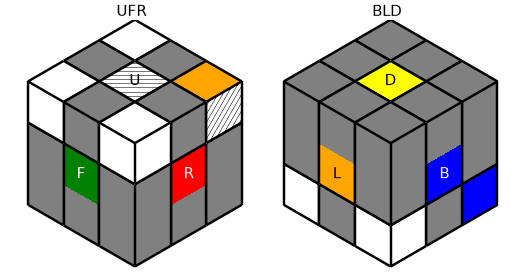

### Case 7

Execute `M14: B L' B' R B L B' L' R' L`.

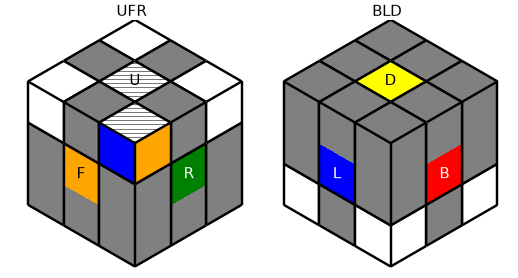

### Case 8

Execute `(((y' (M14) y)^-1)^U)^-1: U' R B' R' F R B R' B' F' B U`.

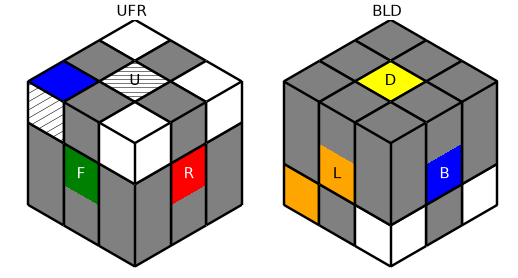

### Case 9

Execute `(M5^-1)^-3: B' R' U' R U R' U' R U R' U' R U B`.

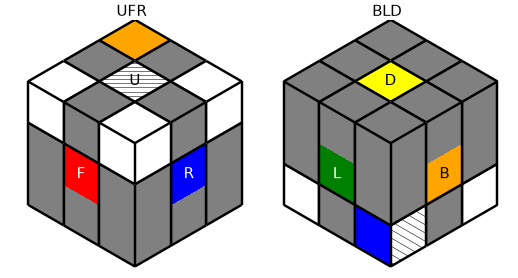

### Case 10

Execute `M6^-3: B L2 F' L' F L F' L' F L F' L' F L' B'`.

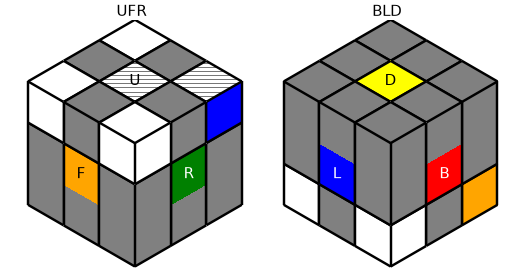

### Case 11

Execute `M14^-1: L' R L B L' B' R' B L B'`.

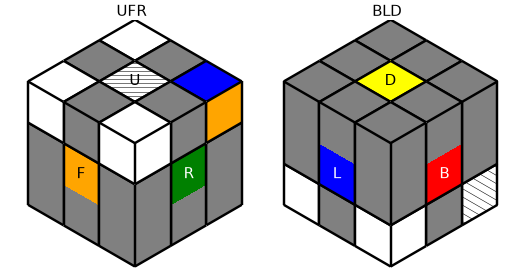

### Case 12

Execute `(((y' (M14) y)^-1)^(U2))^-1: U2 R B' R' F R B R' B' F' B U2`.

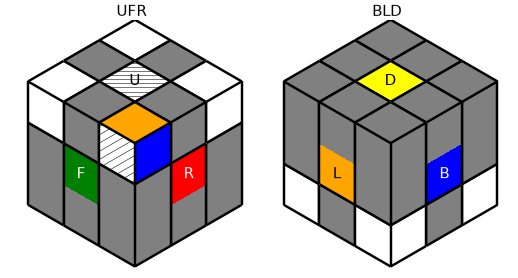

Also correct automatically after this stage: place Corner UBL.

## Stage 8: Solve Corner UBR

This stage has 9 exact cases and 8 instruction families. It reduces the remaining possibilities from 27 to 3.

### Case 1

Skip — already correct

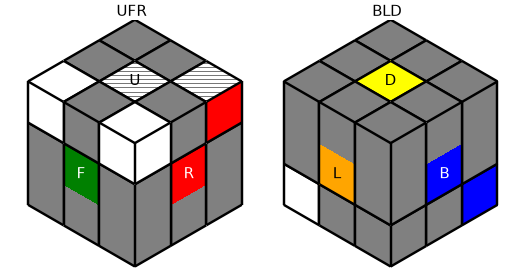

### Case 2

Execute `((y (M6) y')^-1 (y' (M10) y)^-1)^-1: R' F' L F' L' F2 R L F R' F R F2 L'`.

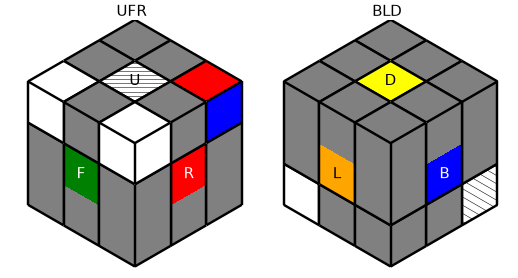

### Case 3

Execute `(y (M7) y' y' (M11) y)^-1: R' U2 R U R' U R L U2 L' U' L U' L'`.

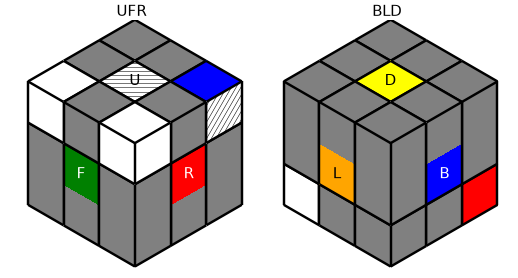

### Case 4

Execute `((y' (M14) y)^(M5^-1))^-1: B' R' U' R U F B R B' R' F' R B R' B' U' R' U R B`.

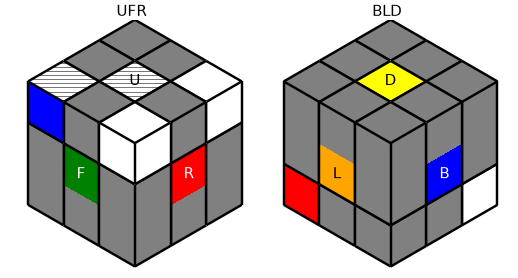

### Case 5

Execute `((y' (M16) y)^U)^-1: U' R B' R2 F R' F' B F R F' R' B' R' B R' U`.

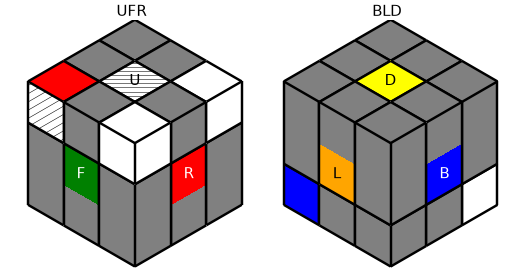

### Case 6

Execute `(((y' (M14) y)^-1)^(U'))^-1: U R B' R' F R B R' B' F' B U'`.

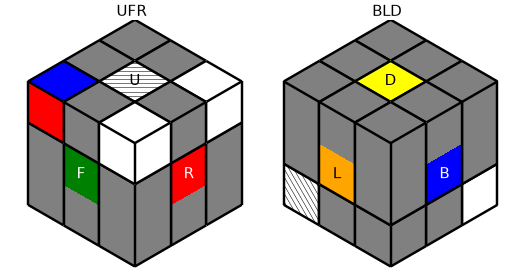

### Case 7

Execute `([U', y (M9) y'])^-1: L U' R' U L' U' R U' R' U L U' R U L' U`.

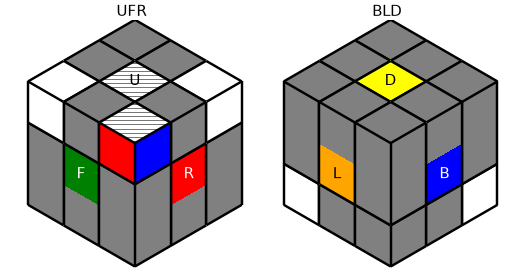

### Case 8

Execute `((y' (M16) y)^((U' y' (M2) y)^-1))^-1: U' R L U2 L' B' R2 F R' F' B F R F' R' B' R' B L U2 L' R' U`.

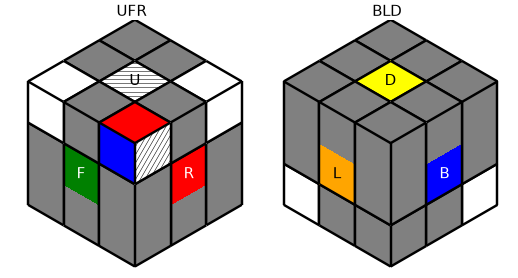

### Case 9

Execute `((y' (M14) y)^(U'))^-1: U B' F B R B' R' F' R B R' U'`.

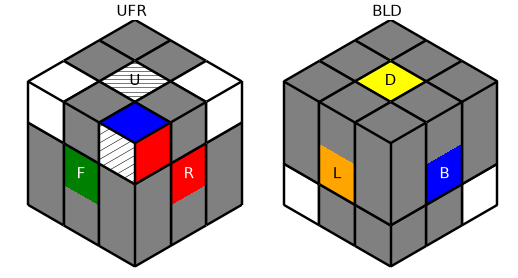

Also correct automatically after this stage: place Corner UBR; place Corner UFL; place Corner UFR.

## Stage 9: Orient Corner UFL

This stage has 3 exact cases and 1 instruction family. It reduces the remaining possibilities from 3 to 1.

### Case 1

Skip — already correct

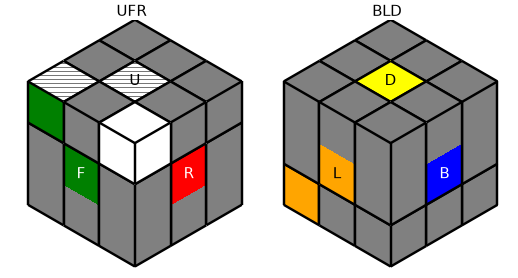

### Case 2

Execute `(M7 y2 (M11) y2)^-1: F' U2 F U F' U F B U2 B' U' B U' B'`.

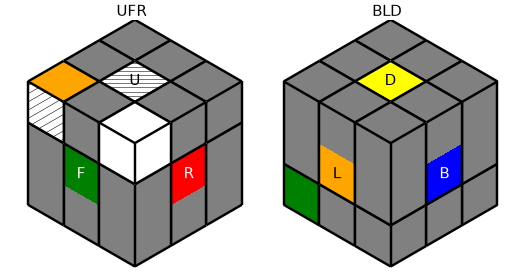

### Case 3

Execute `M7 y2 (M11) y2: B U B' U B U2 B' F' U' F U' F' U2 F`.

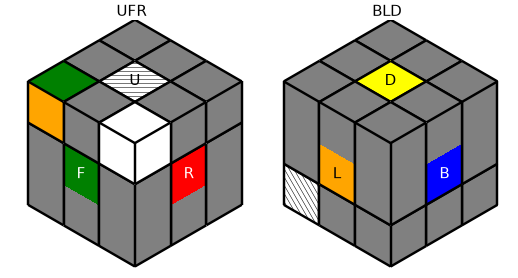

Also correct automatically after this stage: fully solve Corner UFR.

After the final stage every modeled corner and edge sticker is solved. Unmarked center spin and independent virtual-core spin are outside this model.


In [2]:
repertoire = c.template_human_repertoire(analysis, preference=preference, backend="auto",
    optimization_seconds=120, progress=None,
)
display(Markdown(repertoire.write_guide(diagram_mode=diagram_mode, face_colors=face_colors)))


Optional shape graph. Configure and run the following cell when you want to draw the graph. `graph_view="auto"` draws small graphs and summarizes graphs above 1,000 shapes. Use `"local"` for a bounded neighborhood, or explicitly set `graph_view="full"` to draw every shape. Full layouts of large graphs can be expensive.


In [ ]:
import matplotlib.pyplot as plt

graph_view = "auto"  # "summary", "local", or explicit "full"
graph_max_vertices = 1000  # full auto drawings and local neighborhoods are bounded
graph_radius = 2  # used only for the local view
graph_layout = "symmetry"
graph_show_shapes = True
graph_edge_labels = True
graph_figsize = None  # automatic; override with (width, height) in inches
graph_shape_size = None  # automatic; override with a width in inches

shape_graph = c.explore(bandage)
graph_figure = c.draw_bandage_graph(
    shape_graph, view=graph_view, max_vertices=graph_max_vertices, radius=graph_radius,
    layout=graph_layout, show_shapes=graph_show_shapes,
    edge_labels=graph_edge_labels, face_colors=face_colors,
    diagram_mode=diagram_mode, figsize=graph_figsize, shape_size=graph_shape_size,
)
display(graph_figure)
plt.close(graph_figure)


## Generate a scramble

In [3]:
print(c.scramble(bandage))


F U2 B F' L2 B2 R B' R' L2 B' U' F2 L2 B' R2 B L' D L B2 D2 F' D B' R' B R B' R' D' R D2 F' B2 R2 F' B F' B' F' B2 F2 B F B' L2 B' F' U L' B L' B' L' U2 L B L2 B' U' B' U2 L' U2 B
